## 数据分析流程
### 采集数据--确定分析方向--导入数据--数据清洗--数据分析--数据可视化

In [109]:
#1.导入库
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
rcParams['font.family']='microsoft yahei'

In [110]:
#2.导入数据
df = pd.read_csv('../datset/house_sales.csv')
df.head(5)

,city,address,area,floor,name,price,province,rooms,toward,unit,year,origin_url
0,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90㎡,中层（共18层）,圣地亚哥,128万,安徽,3室2厅,南北向,14222元/㎡,2013年建,https://hf.esf.fang.com/chushou/3_404230646.htm
1,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90㎡,中层（共18层）,圣地亚哥,128万,安徽,3室2厅,南北向,14222元/㎡,2013年建,https://hf.esf.fang.com/chushou/3_404230646.htm
2,合肥,生态公园-淮海大道与大众路交口,95㎡,中层（共18层）,正荣·悦都荟,132万,安徽,3室2厅,南向,13895元/㎡,2019年建,https://hf.esf.fang.com/chushou/3_404304901.htm
3,合肥,生态公园-淮海大道与大众路交口,95㎡,中层（共18层）,正荣·悦都荟,132万,安徽,3室2厅,南向,13895元/㎡,2019年建,https://hf.esf.fang.com/chushou/3_404304901.htm
4,合肥,撮镇-文一名门金隅裕溪路与东风大道交口,37㎡,中层（共22层）,文一名门金隅,32万,安徽,2室1厅,南北向,8649元/㎡,2017年建,https://hf.esf.fang.com/chushou/3_404372096.htm


In [1]:
#3.数据概览
print('总记录数：',len(df))
print('字段数量：',len(df.columns))
df.head(5)
# df.info() # 数据类型概览

NameError: name 'df' is not defined

In [112]:
#4.数据的清洗
#第一步删除无用列
df.drop(columns='origin_url',inplace=True)
##检查是否有缺失值
df.isna().sum()
## 删除缺失值数据或者填充数据
df.dropna(inplace=True)
## 检查重复值
df.duplicated().sum()
## 删除重复数据
df.drop_duplicates(inplace=True)


In [113]:
# 面积的数据类型转换
df['area'] = df['area'].str.replace('㎡','').astype(float)

In [114]:
# 售价的数据类型转换
df['price'] = df['price'].str.replace('万','').astype(float)

In [115]:
# 朝向的数据类型转换
df['toward'].value_counts() # 查看是否规范 是否可以为选择 分类
df['toward'] = df['toward'].astype('category') #数据转换为分类

In [116]:
# 单价的类型转换
df['unit'] = df['unit'].str.replace('元/㎡','').astype('int64')

In [117]:
# 年份的数据类型转换
df['year']=df['year'].str.replace('年建','').astype(int)

In [118]:
# 异常值的处理
## 房屋面积异常值的处理
df = df[(df['area']<600) & (df['area']>20)]
## 房屋售价异常值处理 IQR
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1
low_price = q1-1.5*iqr
high_price = q3+1.5*iqr
df=df[(df['price']<high_price) & (df['price']>low_price)]

In [119]:
#5.新数据构造
# 地区 district
df['district']=df['address'].str.split('-').str[0] #取出地区

# 楼层floor——type
df['floor-type']=df['floor'].str.split('（').str[0].astype('category') #字符串取出楼层
def fun1(str1):
    if pd.isna(str1):
        return '未知'
    elif '低' in str1:
        return '低楼层'
    elif '中' in str1:
        return '中楼层'
    else:
        return '高楼层'
df['floor-type2'] = df['floor'].apply(fun1).astype('category') # 函数取出楼层
df.head(5)

# 是否是直辖市 zxs
def fun2(str2):
    if pd.isna(str2):
        return 00
    elif '重庆' in str2:
        return 1
    elif '北京' in str2:
        return 1
    elif '天津市' in str2:
        return 1
    elif '上海' in str2:
        return 1
    else:
        return 0
df['zxs']=df['city'].apply(fun2)
df.head(5)
# 卧室数量bedrooms
df['bedrooms']=df['rooms'].str.split('室').str[0].astype(int)

# 客厅的数量livingrooms
df['livingrooms']=df['rooms'].str.split('室').str[1].str.split('厅').str[0].astype(int) # 字符串取厅前面的数字
#df['rooms'].str.extract('(\d+)厅') # 正则表达式取厅

# 楼龄building_age
df['building_age']=2025 -df['year']

# 价格分段price_labels
df['price_labels'] = pd.cut(df['price'],bins=4,labels=['低价','中价','高价','豪华'])
df.head()

,city,address,area,floor,name,price,province,rooms,toward,unit,year,district,floor-type,floor-type2,zxs,bedrooms,livingrooms,building_age,price_labels
0,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90.0,中层（共18层）,圣地亚哥,128.0,安徽,3室2厅,南北向,14222,2013,龙岗,中层,中楼层,0,3,2,12,中价
2,合肥,生态公园-淮海大道与大众路交口,95.0,中层（共18层）,正荣·悦都荟,132.0,安徽,3室2厅,南向,13895,2019,生态公园,中层,中楼层,0,3,2,6,中价
4,合肥,撮镇-文一名门金隅裕溪路与东风大道交口,37.0,中层（共22层）,文一名门金隅,32.0,安徽,2室1厅,南北向,8649,2017,撮镇,中层,中楼层,0,2,1,8,低价
6,合肥,龙岗-长江东路与和县里交口,50.0,高层（共30层）,柏庄金座,46.0,安徽,2室1厅,南向,9200,2019,龙岗,高层,高楼层,0,2,1,6,低价
8,合肥,新亚汽车站-张洼路与临泉路交汇处向北100米(原红星机械,120.0,中层（共27层）,天目未来,158.0,安徽,4室2厅,南向,13167,2012,新亚汽车站,中层,中楼层,0,4,2,13,高价


In [120]:
#6.问题分析及可视化

Text(0.5, 1.0, '房屋相关性热力图')

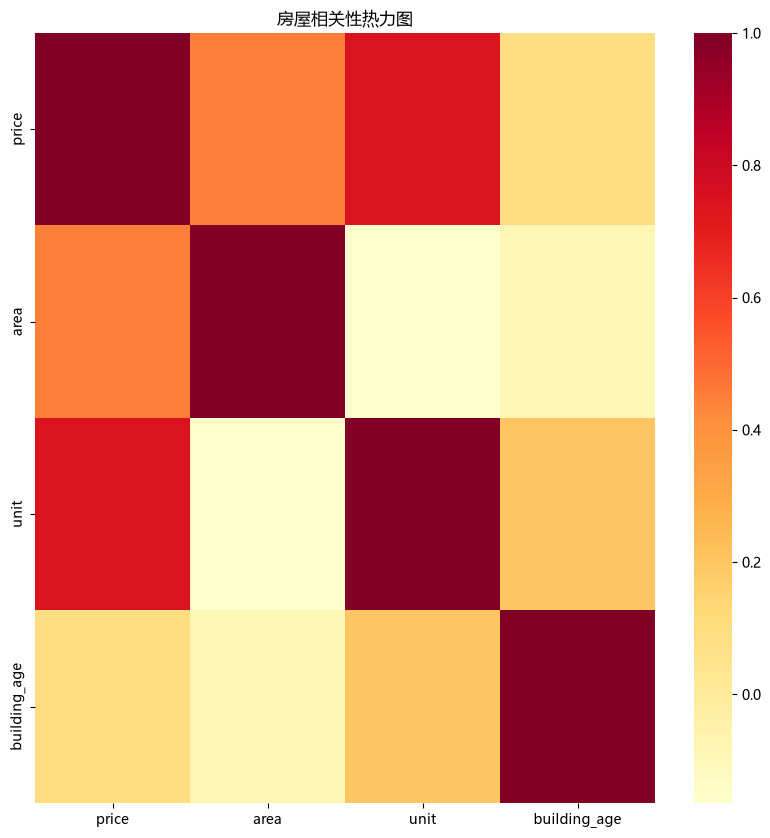

In [121]:
'''
问题编号: A1
问题: 哪些变量最影响房价？面积、楼层、房间数哪个影响更大？
分析主题: 特征相关性
分析目标: 了解房屋各特征对房价的线性影响
分组字段: 无
指标/方法: 皮尔逊相关系数
'''
# 选择数值性特征
a = df[['price','area','unit','building_age']].corr() # 相关系数
# 对房价的影响最大的几个因素的排序
a['price'].sort_values(ascending=False)[1:0] #[1:0]切片选择值
# 相关性热力图
plt.figure(figsize=(10,10))
sns.heatmap(a,cmap='YlOrRd')
plt.title('房屋相关性热力图')


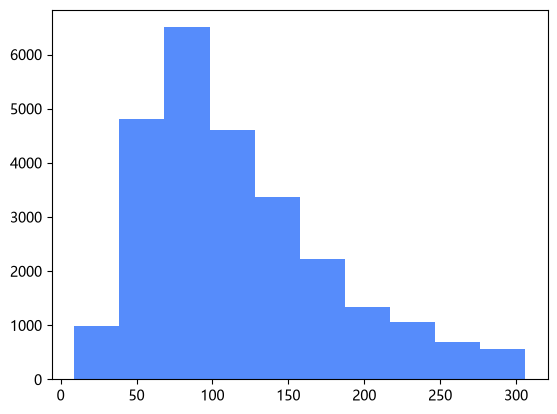

<Axes: xlabel='price', ylabel='Count'>

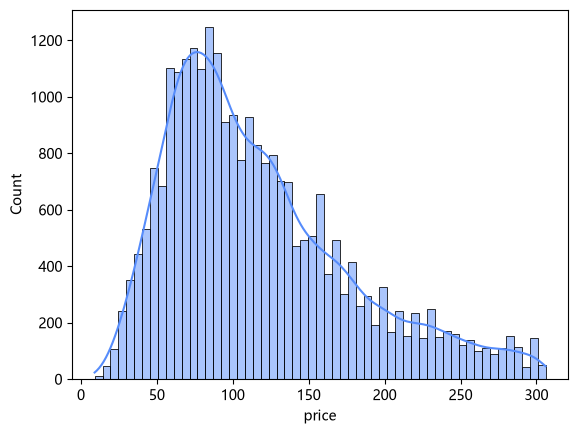

In [130]:
'''
问题编号: A2
问题: 全国房价总体分布是怎样的？是否存在极端值？
分析主题: 描述性统计
分析目标: 概览数值型字段的分布特征
分组字段: 无
指标/方法: 平均数/中位数/四分位数/标准差
'''
df.describe()
# 房价分布直方图
plt.subplot(111)
plt.hist(df['price'],bins=10)
plt.show()
sns.histplot(data=df,x='price',kde=True) # sns画的方法 kde是核密度分布线

In [123]:
'''
问题编号: A3
问题: 哪些城市房价最高？直辖市与非直辖市差异如何？
分析主题: 城市对比
分析目标: 比较不同城市房价水平
分组字段: city
指标/方法: 均价/单价中位数/箱线图
'''

'\n问题编号: A3\n问题: 哪些城市房价最高？直辖市与非直辖市差异如何？\n分析主题: 城市对比\n分析目标: 比较不同城市房价水平\n分组字段: city\n指标/方法: 均价/单价中位数/箱线图\n'

In [124]:
'''
问题编号: A4
问题: 高价房在面积、楼层等方面有什么特征？
分析主题: 价格分层
分析目标: 识别不同价位房屋特征差异
分组字段: 价格分段(低中高)
指标/方法: 列联表/卡方检验
'''
"""A4 价格分层特征差异分析"""

'A4 价格分层特征差异分析'

In [125]:
'''
问题编号: A5
问题: 哪种户型最受欢迎？三室比两室贵多少？
分析主题: 户型分析
分析目标: 分析不同户型的市场表现
分组字段: rooms
指标/方法: 占比/平均单价/溢价率
'''

'\n问题编号: A5\n问题: 哪种户型最受欢迎？三室比两室贵多少？\n分析主题: 户型分析\n分析目标: 分析不同户型的市场表现\n分组字段: rooms\n指标/方法: 占比/平均单价/溢价率\n'

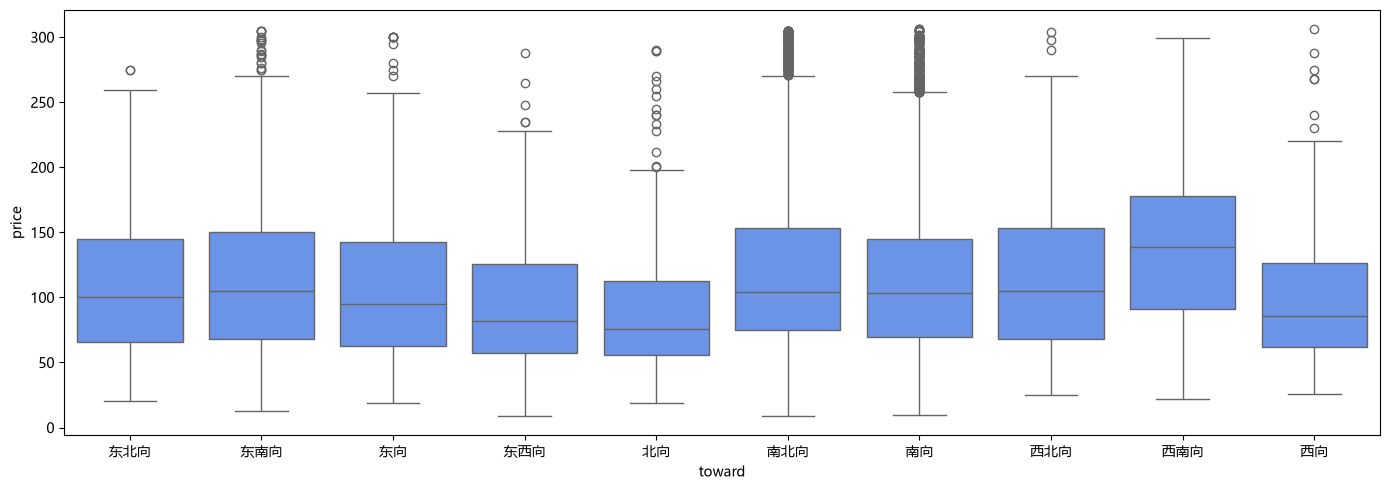

toward
南北向    14884
南向      8796
东南向      974
东向       419
北向       258
西南向      254
西向       161
东西向      151
西北向      133
东北向      105
Name: count, dtype: int64

In [136]:
'''
问题编号: A6
问题: 南北向是否真比单一朝向贵？贵多少？
分析主题: 朝向溢价
分析目标: 评估不同朝向的价格差异
分组字段: toward
指标/方法: 方差分析/多重比较
'''
df['toward'].value_counts()
df.groupby('toward').agg({
    'price':['mean','median'],
    'unit':['median'],
    'building_age':['mean'],
})

#数据可视化
plt.figure(figsize=(14,5))
sns.boxplot(x='toward',y='price',data=df)
plt.tight_layout()
plt.show()
df['toward'].value_counts()